# Practical 11: Continuous Predictive Modeling with Linear Regression

**UNIT 3: Preparing Big Data for Machine Learning**

**Problem Statement:** Write a Python program to build, train, and evaluate a Linear Regression model using Scikit-Learn. Fit the model to predict salary based on years of experience, display model coefficients (slope and intercept), predict outcomes on the test dataset, and calculate Mean Squared Error (MSE) and R-squared (R2) score.

,YearsExperience,Salary
0,1.5,47987.0
1,1.9,41157.0
2,2.2,49282.0
3,2.5,52724.0
4,3.5,55881.0


Train size: 38 | Test size: 7
Slope (coefficient): 8,828.79   -> salary rises by this much per extra year
Intercept           : 27,910.57
Equation            : Salary = 27,910.57 + 8,828.79 x Experience

,Experience,Actual,Predicted
0,7.1,91640.0,90595.0
1,6.7,87645.0,87063.0
2,5.3,64087.0,74703.0
3,7.6,87393.0,95009.0
4,1.9,41157.0,44685.0
5,4.7,70030.0,69406.0
6,5.6,73030.0,77352.0


MSE  : 29,094,019.16
RMSE : 5,393.89
R²   : 0.8910
Predicted salary for 5.5 years of experience: 76,469

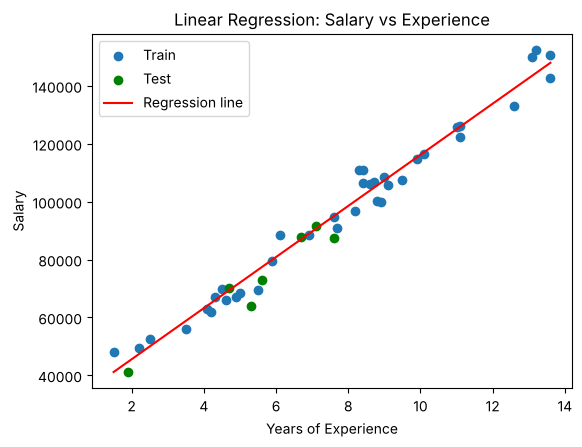

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

rg = np.random.default_rng(99)
n = 45
experience = np.sort(np.round(rg.uniform(1, 14, n), 1))
salary = np.round(26000 + 9000 * experience + rg.normal(0, 5000, n), 0)
frame = pd.DataFrame({"YearsExperience": experience, "Salary": salary})
print(frame.head())

X = frame[["YearsExperience"]]
y = frame["Salary"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=7)
print("Train size:", len(X_train), "| Test size:", len(X_test))

lr = LinearRegression()
lr.fit(X_train, y_train)

print(f"Slope (coefficient): {lr.coef_[0]:,.2f}   -> salary rises by this much per extra year")
print(f"Intercept           : {lr.intercept_:,.2f}")
print(f"Equation            : Salary = {lr.intercept_:,.2f} + {lr.coef_[0]:,.2f} x Experience")

y_pred = lr.predict(X_test)
eval_df = pd.DataFrame({"Experience": X_test["YearsExperience"].values,
                           "Actual": y_test.values,
                           "Predicted": y_pred.round(0)})
print(eval_df)

mse = mean_squared_error(y_test, y_pred)
print(f"MSE  : {mse:,.2f}")
print(f"RMSE : {np.sqrt(mse):,.2f}")
print(f"R²   : {r2_score(y_test, y_pred):.4f}")

new = pd.DataFrame({"YearsExperience": [5.5]})
print(f"Predicted salary for 5.5 years of experience: {lr.predict(new)[0]:,.0f}")

plt.scatter(X_train, y_train, label="Train")
plt.scatter(X_test, y_test, color="green", label="Test")
plt.plot(X, lr.predict(X), color="red", label="Regression line")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Linear Regression: Salary vs Experience")
plt.legend()
plt.show()